In [85]:
import json
from pathlib import Path
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

# Locate the profiler directory from either the notebook folder or repository root.
search_roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / "PerfProfiler"]
profiler_root = next((root for root in search_roots
                      if (root / "Predict_result" / "econ_results.json").is_file()), None)
if profiler_root is None:
    raise FileNotFoundError("Could not locate PerfProfiler/Predict_result/econ_results.json")

with (profiler_root / "Predict_result" / "econ_results.json").open(encoding="utf-8") as file:
    econ_results = json.load(file)

# Load execution-time means from the result file.
exe_time_path = profiler_root / "Predict_result" / "exe_time_results.json"
if not exe_time_path.is_file():
    raise FileNotFoundError("Run python PerfProfiler/exe_time.py before plotting.")
with exe_time_path.open(encoding="utf-8") as file:
    exe_time_results = json.load(file)
exe_time_by_configuration = {
    (row["workload"], row["batch_size"], row["gpu"], row["gpu_count"]): row
    for row in exe_time_results["rows"]
}
econ_by_configuration = {
    (row["workload"], row["batch_size"], row["gpu"], row["gpu_count"]): row
    for row in econ_results["rows"]
}


In [86]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'Times New Roman'
rcParams['font.size'] = 20
rcParams['text.usetex'] = True
rcParams['text.latex.preamble'] = r'''
\usepackage{inconsolata}
\usepackage{newtxtext}  % Use Times as the main text font when available.
'''

In [87]:
cycleGAN_batch_size = 2
ResNet50_batch_size = 256
Transformer_batch_size = 1024
Qwen_batch_size = 2
workload_list = ["cycleGAN-Pytorch", "ResNet50-Pytorch", "Transformers-Pytorch", "Qwen"]
GPU_model_list = ["P100-SXM2-16GB", "V100-SXM2-16GB", "A100-PCIE-40GB"]
workload_batch_size_mapping = {
    "cycleGAN-Pytorch": cycleGAN_batch_size,
    "ResNet50-Pytorch": ResNet50_batch_size,
    "Transformers-Pytorch": Transformer_batch_size,
    "Qwen": Qwen_batch_size
}

cycleGAN-Pytorch


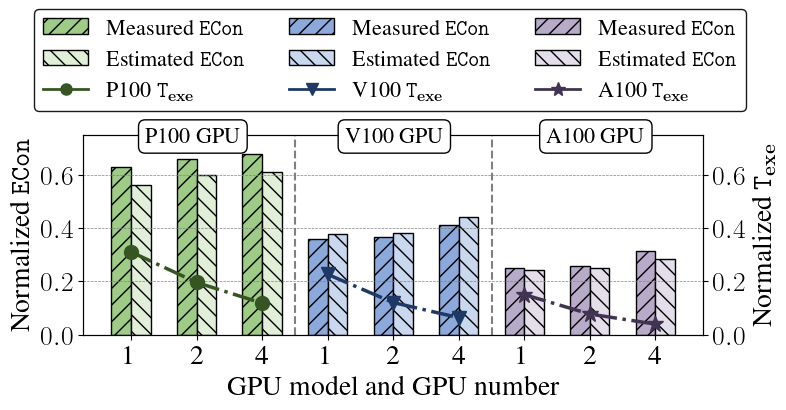

[0.10631760939959571, 0.0920035235473612, 0.0978190793198569, 0.04632540901295397, 0.043031988561117576, 0.07172935006916532, 0.02960605078921621, 0.02960605078921624, 0.09661272911676975]
0.06811686562280587


In [88]:
workload = workload_list[0]
print(workload)
x_labels = []
predicted_ECon = []
actual_ECon = []
batch_sizes = workload_batch_size_mapping[workload]
gpu_num_list = [1, 2, 4]
gpu_models = GPU_model_list
# Group the data by GPU model, then by GPU count.
for gpu in gpu_models:
    for gpu_num in gpu_num_list:
        x_labels.append(f'{gpu}-{gpu_num}')
        actual_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_measured_econ"])
        predicted_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_estimated_econ"])

x = np.arange(len(x_labels))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 2.6))

# Assign separate color palettes to GPU groups.
bar_colors_predicted = []
bar_colors_actual = []
color_map_predicted = {'P100': '#9ecb85', 'V100': '#8ca9dc', 'A100': '#b7abc9'}
color_map_actual = {'P100': '#e1efd9', 'V100': '#c9d7ef', 'A100': '#e3deea'}

for label in x_labels:
    gpu = label.split('-')[0]
    bar_colors_predicted.append(color_map_predicted[gpu])
    bar_colors_actual.append(color_map_actual[gpu])


# Draw the measured and estimated ECon bars.
ax.bar(x - width / 2, actual_ECon, width, label='Measured ECon', color=bar_colors_predicted, edgecolor='black', hatch='//')
ax.bar(x + width / 2, predicted_ECon, width, label='Estimated ECon', color=bar_colors_actual, edgecolor='black', hatch='\\\\')

ax.set_xlabel('GPU model and GPU number')
ax.set_ylabel(r'Normalized $\mathtt{ECon}$')
ax.set_xticks(x)
ax.set_xticklabels([1,2,4,1,2,4,1,2,4], rotation=0)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')

# Separate the GPU model groups.
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=1, color='gray', linestyle='--')

# Add a secondary y-axis for execution time.
ax2 = ax.twinx()
ax2.set_ylabel(r'Normalized $\mathtt{T}_{\mathbf{exe}}$', color='black')
ax2.set_ylim(0, 1.0)

# Prepare line positions in the same GPU grouping order.
x_group = [np.arange(i*3, (i+1)*3) for i in range(len(gpu_models))]  # Positions for three GPUs, with three counts per GPU.

line_colors = ['#375523', '#1f3967', '#403452']  # Colors for each GPU model.
norm_exec_time_dict = {}
for gpu in gpu_models:
    times = []
    for gpu_num in gpu_num_list:
        times.append(exe_time_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["mean_normalized_exe_time"])
    norm_exec_time_dict[gpu] = times

marker_styles = ['o', 'v', '*']
marker_size = [10, 10, 12]
for i, gpu in enumerate(gpu_models):
    y = norm_exec_time_dict[gpu]
    ax2.plot(
        x_group[i],
        y,
        marker=marker_styles[i],
        label=f'{gpu} Exec. Time',
        color=line_colors[i],
        linestyle='-.',
        linewidth=2.5,
        markersize=marker_size[i]
    )

ax2.set_ylim(0, 0.75)
ax.set_ylim(0, 0.75)
ax.set_yticks([0, 0.2, 0.4, 0.6])
ax2.set_yticks([0, 0.2, 0.4, 0.6])

# Label each GPU group.
gpu_num_texts = ["P100 GPU", "V100 GPU", "A100 GPU"]
gpu_num_xpos = [0.1, 0.422, 0.747]

for xpos, text in zip(gpu_num_xpos, gpu_num_texts):
    plt.text(xpos, 1.04, text,
             ha='left', va='top', transform=plt.gca().transAxes,
             fontsize=16, color='black',
             bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

# Combine the bar and line legend handles.
bar_handles  = [
    mpatches.Patch(facecolor=color_map_predicted['P100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['P100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[0], marker=marker_styles[0], markersize=8, linewidth=2, label='P100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['V100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['V100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[1], marker=marker_styles[1], markersize=8, linewidth=2, label=r'V100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['A100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['A100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[2], marker=marker_styles[2], markersize=10, linewidth=2, label='A100 $\mathtt{T}_{\mathbf{exe}}$')
]

legend = ax.legend(
    handles=bar_handles,
    loc='upper center',
    bbox_to_anchor=(0.495, 1.68),
    ncol=3,
    fontsize=16,
    frameon=True,
    fancybox=True,
    framealpha=1,
    edgecolor='black'
)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_alpha(0.9)
plt.savefig('cycleGAN_ECon.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_ECon, predicted_ECon)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)

ResNet50-Pytorch


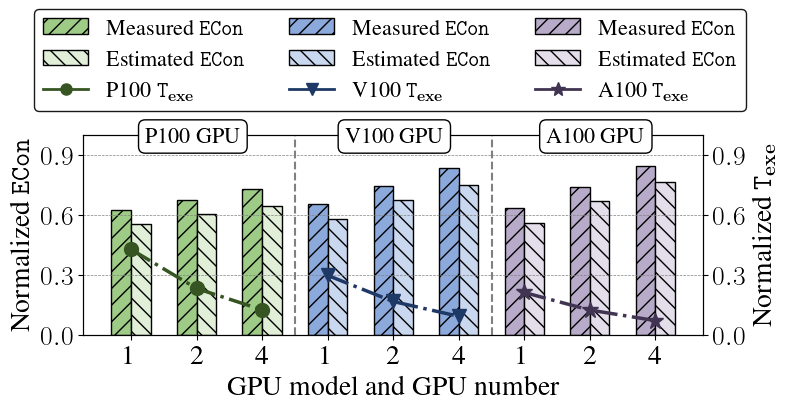

[0.10858543239941454, 0.10718840466588866, 0.11222819343014945, 0.1142070104567032, 0.09344284187059658, 0.10124170324948106, 0.11374460787498986, 0.09211474233237528, 0.09650629977050806]
0.10436213733890075


In [89]:
 workload = workload_list[1]
print(workload)
x_labels = []
predicted_ECon = []
actual_ECon = []
batch_sizes = workload_batch_size_mapping[workload]
gpu_num_list = [1, 2, 4]
# Group the data by GPU model, then by GPU count.
for gpu in gpu_models:
    for gpu_num in gpu_num_list:
        x_labels.append(f'{gpu}-{gpu_num}')
        actual_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_measured_econ"])
        predicted_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_estimated_econ"])

x = np.arange(len(x_labels))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 2.6))

# Assign separate color palettes to GPU groups.
bar_colors_predicted = []
bar_colors_actual = []
color_map_predicted = {'P100': '#9ecb85', 'V100': '#8ca9dc', 'A100': '#b7abc9'}
color_map_actual = {'P100': '#e1efd9', 'V100': '#c9d7ef', 'A100': '#e3deea'}

for label in x_labels:
    gpu = label.split('-')[0]
    bar_colors_predicted.append(color_map_predicted[gpu])
    bar_colors_actual.append(color_map_actual[gpu])


# Draw the measured and estimated ECon bars.
ax.bar(x - width / 2, actual_ECon, width, label='Measured ECon', color=bar_colors_predicted, edgecolor='black', hatch='//')
ax.bar(x + width / 2, predicted_ECon, width, label='Estimated ECon', color=bar_colors_actual, edgecolor='black', hatch='\\\\')

ax.set_xlabel('GPU model and GPU number')
ax.set_ylabel(r'Normalized $\mathtt{ECon}$')
ax.set_xticks(x)
ax.set_xticklabels([1,2,4,1,2,4,1,2,4], rotation=0)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')

# Separate the GPU model groups.
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=1, color='gray', linestyle='--')

# Add a secondary y-axis for execution time.
ax2 = ax.twinx()
ax2.set_ylabel(r'Normalized $\mathtt{T}_{\mathbf{exe}}$', color='black')
ax2.set_ylim(0, 1.0)

# Prepare line positions in the same GPU grouping order.
x_group = [np.arange(i*3, (i+1)*3) for i in range(len(gpu_models))]  # Positions for three GPUs, with three counts per GPU.

line_colors = ['#375523', '#1f3967', '#403452']  # Colors for each GPU model.
norm_exec_time_dict = {}
for gpu in gpu_models:
    times = []
    for gpu_num in gpu_num_list:
        times.append(exe_time_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["mean_normalized_exe_time"])
    norm_exec_time_dict[gpu] = times

marker_styles = ['o', 'v', '*']
marker_size = [10, 10, 12]
for i, gpu in enumerate(gpu_models):
    y = norm_exec_time_dict[gpu]
    ax2.plot(
        x_group[i],
        y,
        marker=marker_styles[i],
        label=f'{gpu} Exec. Time',
        color=line_colors[i],
        linestyle='-.',
        linewidth=2.5,
        markersize=marker_size[i]
    )

ax2.set_ylim(0, 1)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.3, 0.6, 0.9])
ax2.set_yticks([0, 0.3, 0.6, 0.9])

# Label each GPU group.
gpu_num_texts = ["P100 GPU", "V100 GPU", "A100 GPU"]
gpu_num_xpos = [0.1, 0.422, 0.747]

for xpos, text in zip(gpu_num_xpos, gpu_num_texts):
    plt.text(xpos, 1.04, text,
             ha='left', va='top', transform=plt.gca().transAxes,
             fontsize=16, color='black',
             bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

# Combine the bar and line legend handles.
bar_handles  = [
    mpatches.Patch(facecolor=color_map_predicted['P100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['P100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[0], marker=marker_styles[0], markersize=8, linewidth=2, label='P100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['V100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['V100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[1], marker=marker_styles[1], markersize=8, linewidth=2, label='V100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['A100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['A100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[2], marker=marker_styles[2], markersize=10, linewidth=2, label='A100 $\mathtt{T}_{\mathbf{exe}}$')
]

legend = ax.legend(
    handles=bar_handles,
    loc='upper center',
    bbox_to_anchor=(0.495, 1.68),
    ncol=3,
    fontsize=16,
    frameon=True,
    fancybox=True,
    framealpha=1,
    edgecolor='black'
)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_alpha(0.9)
plt.savefig('ResNet50_ECon.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_ECon, predicted_ECon)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)

Transformers-Pytorch


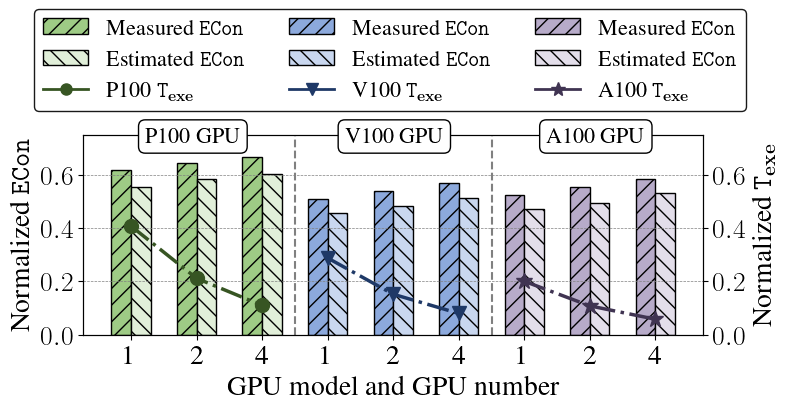

[0.10318765470331041, 0.09203896309772755, 0.09604550288953126, 0.10656190082942008, 0.1041114313376996, 0.09654825520764504, 0.10514615032742214, 0.11029167803233633, 0.09157341960898652]
0.10061166178156432


In [90]:
workload = workload_list[2]
print(workload)
x_labels = []
predicted_ECon = []
actual_ECon = []
batch_sizes = workload_batch_size_mapping[workload]
gpu_num_list = [1, 2, 4]
# Group the data by GPU model, then by GPU count.
for gpu in gpu_models:
    for gpu_num in gpu_num_list:
        x_labels.append(f'{gpu}-{gpu_num}')
        actual_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_measured_econ"])
        predicted_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_estimated_econ"])

x = np.arange(len(x_labels))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 2.6))

# Assign separate color palettes to GPU groups.
bar_colors_predicted = []
bar_colors_actual = []
color_map_predicted = {'P100': '#9ecb85', 'V100': '#8ca9dc', 'A100': '#b7abc9'}
color_map_actual = {'P100': '#e1efd9', 'V100': '#c9d7ef', 'A100': '#e3deea'}

for label in x_labels:
    gpu = label.split('-')[0]
    bar_colors_predicted.append(color_map_predicted[gpu])
    bar_colors_actual.append(color_map_actual[gpu])


# Draw the measured and estimated ECon bars.
ax.bar(x - width / 2, actual_ECon, width, label='Measured ECon', color=bar_colors_predicted, edgecolor='black', hatch='//')
ax.bar(x + width / 2, predicted_ECon, width, label='Estimated ECon', color=bar_colors_actual, edgecolor='black', hatch='\\\\')

ax.set_xlabel('GPU model and GPU number')
ax.set_ylabel(r'Normalized $\mathtt{ECon}$')
ax.set_xticks(x)
ax.set_xticklabels([1,2,4,1,2,4,1,2,4], rotation=0)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')

# Separate the GPU model groups.
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=1, color='gray', linestyle='--')

# Add a secondary y-axis for execution time.
ax2 = ax.twinx()
ax2.set_ylabel(r'Normalized $\mathtt{T}_{\mathbf{exe}}$', color='black')

# Prepare line positions in the same GPU grouping order.
x_group = [np.arange(i*3, (i+1)*3) for i in range(len(gpu_models))]  # Positions for three GPUs, with three counts per GPU.

line_colors = ['#375523', '#1f3967', '#403452']  # Colors for each GPU model.
norm_exec_time_dict = {}
for gpu in gpu_models:
    times = []
    for gpu_num in gpu_num_list:
        times.append(exe_time_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["mean_normalized_exe_time"])
    norm_exec_time_dict[gpu] = times

marker_styles = ['o', 'v', '*']
marker_size = [10, 10, 12]
for i, gpu in enumerate(gpu_models):
    y = norm_exec_time_dict[gpu]
    ax2.plot(
        x_group[i],
        y,
        marker=marker_styles[i],
        label=f'{gpu} Exec. Time',
        color=line_colors[i],
        linestyle='-.',
        linewidth=2.5,
        markersize=marker_size[i]
    )

ax2.set_ylim(0, 0.75)
ax.set_ylim(0, 0.75)
ax.set_yticks([0, 0.2, 0.4, 0.6])
ax2.set_yticks([0, 0.2, 0.4, 0.6])

# Label each GPU group.
gpu_num_texts = ["P100 GPU", "V100 GPU", "A100 GPU"]
gpu_num_xpos = [0.1, 0.422, 0.747]

for xpos, text in zip(gpu_num_xpos, gpu_num_texts):
    plt.text(xpos, 1.04, text,
             ha='left', va='top', transform=plt.gca().transAxes,
             fontsize=16, color='black',
             bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

# Combine the bar and line legend handles.
bar_handles  = [
    mpatches.Patch(facecolor=color_map_predicted['P100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['P100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[0], marker=marker_styles[0], markersize=8, linewidth=2, label='P100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['V100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['V100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[1], marker=marker_styles[1], markersize=8, linewidth=2, label='V100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['A100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['A100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[2], marker=marker_styles[2], markersize=10, linewidth=2, label='A100 $\mathtt{T}_{\mathbf{exe}}$')
]

legend = ax.legend(
    handles=bar_handles,
    loc='upper center',
    bbox_to_anchor=(0.495, 1.68),
    ncol=3,
    fontsize=16,
    frameon=True,
    fancybox=True,
    framealpha=1,
    edgecolor='black'
)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_alpha(0.9)
plt.savefig('Transformers_ECon.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_ECon, predicted_ECon)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)

Qwen


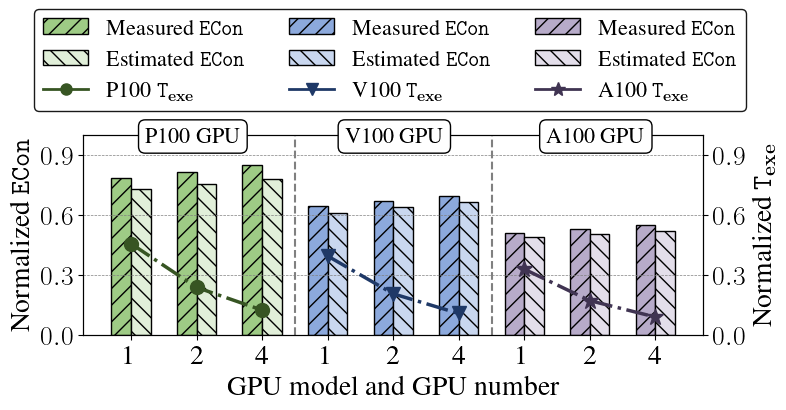

[0.07095587655014482, 0.07847821441969943, 0.08347544090486185, 0.05168064174597595, 0.04253753758672527, 0.04185802117022116, 0.042587778763244336, 0.052722313842749446, 0.056362191164606446]
0.05785089068313652


In [91]:
workload = workload_list[3]
print(workload)
x_labels = []
predicted_ECon = []
actual_ECon = []
batch_sizes = workload_batch_size_mapping[workload]
gpu_num_list = [1, 2, 4]
gpu_models = GPU_model_list
# Group the data by GPU model, then by GPU count.
for gpu in gpu_models:
    for gpu_num in gpu_num_list:
        x_labels.append(f'{gpu}-{gpu_num}')
        actual_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_measured_econ"])
        predicted_ECon.append(econ_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["predicted_estimated_econ"])

x = np.arange(len(x_labels))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 2.6))

# Assign separate color palettes to GPU groups.
bar_colors_predicted = []
bar_colors_actual = []
color_map_predicted = {'P100': '#9ecb85', 'V100': '#8ca9dc', 'A100': '#b7abc9'}
color_map_actual = {'P100': '#e1efd9', 'V100': '#c9d7ef', 'A100': '#e3deea'}

for label in x_labels:
    gpu = label.split('-')[0]
    bar_colors_predicted.append(color_map_predicted[gpu])
    bar_colors_actual.append(color_map_actual[gpu])


# Draw the measured and estimated ECon bars.
ax.bar(x - width / 2, actual_ECon, width, label='Measured ECon', color=bar_colors_predicted, edgecolor='black', hatch='//')
ax.bar(x + width / 2, predicted_ECon, width, label='Estimated ECon', color=bar_colors_actual, edgecolor='black', hatch='\\\\')

ax.set_xlabel('GPU model and GPU number')
ax.set_ylabel(r'Normalized $\mathtt{ECon}$')
ax.set_xticks(x)
ax.set_xticklabels([1,2,4,1,2,4,1,2,4], rotation=0)
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5, color='gray')

# Separate the GPU model groups.
for pos in [2.5, 5.5]:
    ax.axvline(x=pos, ymin=0, ymax=1, color='gray', linestyle='--')

# Add a secondary y-axis for execution time.
ax2 = ax.twinx()
ax2.set_ylabel(r'Normalized $\mathtt{T}_{\mathbf{exe}}$', color='black')
ax2.set_ylim(0, 1.0)

# Prepare line positions in the same GPU grouping order.
x_group = [np.arange(i*3, (i+1)*3) for i in range(len(gpu_models))]  # Positions for three GPUs, with three counts per GPU.

line_colors = ['#375523', '#1f3967', '#403452']  # Colors for each GPU model.
norm_exec_time_dict = {}
for gpu in gpu_models:
    times = []
    for gpu_num in gpu_num_list:
        times.append(exe_time_by_configuration[(workload, batch_sizes, gpu, gpu_num)]["mean_normalized_exe_time"])
    norm_exec_time_dict[gpu] = times

marker_styles = ['o', 'v', '*']
marker_size = [10, 10, 12]
for i, gpu in enumerate(gpu_models):
    y = norm_exec_time_dict[gpu]
    ax2.plot(
        x_group[i],
        y,
        marker=marker_styles[i],
        label=f'{gpu} Exec. Time',
        color=line_colors[i],
        linestyle='-.',
        linewidth=2.5,
        markersize=marker_size[i]
    )

ax2.set_ylim(0, 1)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.3, 0.6, 0.9])
ax2.set_yticks([0, 0.3, 0.6, 0.9])

# Label each GPU group.
gpu_num_texts = ["P100 GPU", "V100 GPU", "A100 GPU"]
gpu_num_xpos = [0.1, 0.422, 0.747]

for xpos, text in zip(gpu_num_xpos, gpu_num_texts):
    plt.text(xpos, 1.04, text,
             ha='left', va='top', transform=plt.gca().transAxes,
             fontsize=16, color='black',
             bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=1.0))

# Combine the bar and line legend handles.
bar_handles  = [
    mpatches.Patch(facecolor=color_map_predicted['P100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['P100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[0], marker=marker_styles[0], markersize=8, linewidth=2, label='P100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['V100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['V100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[1], marker=marker_styles[1], markersize=8, linewidth=2, label='V100 $\mathtt{T}_{\mathbf{exe}}$'),

    mpatches.Patch(facecolor=color_map_predicted['A100'], label=r'Measured $\mathtt{ECon}$', edgecolor='black', hatch='//'),
    mpatches.Patch(facecolor=color_map_actual['A100'], label=r'Estimated $\mathtt{ECon}$', edgecolor='black', hatch='\\\\'),
    Line2D([0], [0], color=line_colors[2], marker=marker_styles[2], markersize=10, linewidth=2, label='A100 $\mathtt{T}_{\mathbf{exe}}$')
]

legend = ax.legend(
    handles=bar_handles,
    loc='upper center',
    bbox_to_anchor=(0.495, 1.68),
    ncol=3,
    fontsize=16,
    frameon=True,
    fancybox=True,
    framealpha=1,
    edgecolor='black'
)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_alpha(0.9)
plt.savefig('Qwen_ECon.pdf', format='pdf', bbox_inches='tight')
plt.show()

relative_errors = [abs(p - a) / a for a, p in zip(actual_ECon, predicted_ECon)]
avg_relative_errors = sum(relative_errors) / len(relative_errors)
print(relative_errors)
print(avg_relative_errors)